# Vibrational Normal-Mode Analysis

In [1]:
import csv
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import scope
from scope.vnm_tools import map_vnms

sys.path.insert(0, os.path.abspath('..'))
from atlas_functions import (
    assess_vnm_mapping,
    bin_mode_contributions,
    find_optimized_minimum,
    get_atomic_frequency_shifts,
    get_ligand_metal_weights,
    get_mode_enthalpies,
    get_mode_entropies,
    get_weighted_frequency_metrics,
    plot_binned_vnm_group_contributions,
    plot_representative_frequency_shifts,
    plot_vnm_mapping_summary,
    project_vnms_on_fcs,
    read_csv,
    write_csv_rows,
)

In [2]:
data_path              = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                    # Update with your path
analysis_path          = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/"  # Update with your path 
env_path               = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy" # Update with your path
save_figures           = True
overwrite_vnm_mappings = False
temperature            = 298.15
frequency_bins         = np.asarray([1, 50, 100, 200, 400, 600, 800, 1600, 4000], dtype=float)
group_order            = ['d=1', 'd=2', 'd=3', 'd=6', 'heteroleptic']

# Figures Path
if save_figures: figures_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/"       # Update with your path
else:            figures_path = None 

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path     = analysis_path + "Outputs/"
vnm_mapping_path = analysis_path + "Notebooks/VNM_Mappings/"

# Checks Scope Version
expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# This folders are required, together with the system-dedicated folders inside
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)
os.makedirs(vnm_mapping_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"VNM mappings:       {vnm_mapping_path}")
print(f"Overwrite mappings: {overwrite_vnm_mappings}")
print(f"Manuscript Figures: {figures_path}")

SCOPE version:      0.9.6
Data directory:     /Users/sergivela/Documents/SCOPE/ATLAS/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/
VNM mappings:       /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Notebooks/VNM_Mappings/
Overwrite mappings: False
Manuscript Figures: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/


## 1. Prepares VNMs for analysis

### Loads Systems

In [3]:
unique_csv_path     = outputs_path + "unique_systems.csv"

unique_systems = []
with open(unique_csv_path, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        sys = scope.load_binary(f"{data_path}/{row['path']}")
        sys.set_paths_from_environment(env)
        unique_systems.append(sys)

print("Unique Systems:", len(unique_systems))

Unique Systems: 602


### Loads or recomputes the reordered VNMs

In [4]:
vnm_mapping_by_refcode = {}
mapping_summary_rows   = []
mapping_errors         = []
num_loaded             = 0
num_computed           = 0
mapping_summary_path   = outputs_path + "vnm_mapping_summary.csv"

for idx, sys in enumerate(unique_systems):
    refcode     = sys.refcode_wo_digits
    binary_path = vnm_mapping_path + refcode + "_vnm_mapping.npy"

    try:
        if os.path.isfile(binary_path) and not overwrite_vnm_mappings:
            vnm_mapping = scope.load_binary(binary_path)
            status = "loaded"
            num_loaded += 1

        else:
            hs_min = find_optimized_minimum(sys.find_source("ref_hs_mol")[1])[1]
            ls_min = find_optimized_minimum(sys.find_source("ref_ls_mol")[1])[1]

            # Re-parses eigenvectors only when they are not already stored.
            for st in [hs_min, ls_min]:
                modes_are_stored = (
                    hasattr(st, "VNMs")
                    and st.VNMs is not None
                    and len(st.VNMs) > 0
                    and all(getattr(vnm, "has_mode", False) and hasattr(vnm, "is_mass_weighted") for vnm in st.VNMs)
                )
                if modes_are_stored: continue

                for comp in st.computations:
                    if comp.type == "freq":
                        if not hasattr(comp, "output"):
                            comp.create_output()
                        VNMs = comp.output.get_vnms(witheigen=True)
                        st.set_VNMs(VNMs)

            # Computed Mapping
            vnmsA_ordered, vnmsB_ordered, results = map_vnms(hs_min.VNMs, ls_min.VNMs, hs_min.labels, hs_min.coord, ls_min.labels, ls_min.coord, adjmatA=hs_min.molecules[0].adjmat, adjmatB=ls_min.molecules[0].adjmat, debug=0)

            # Prepares Intermediate Cache of results
            vnm_mapping = {
                "vnmsA_ordered": vnmsA_ordered,
                "vnmsB_ordered": vnmsB_ordered,
                "mappings": results["mappings"],
                "alignment": results["alignment"],
            }

            scope.save_binary(vnm_mapping, binary_path)
            status = "computed"
            num_computed += 1

        vnm_mapping_by_refcode[refcode] = vnm_mapping
        metrics = assess_vnm_mapping(vnm_mapping["mappings"])
        summary_row = {"refcode": refcode, "binary_path": binary_path, "status": status, "error": ""}
        summary_row.update(metrics)
        mapping_summary_rows.append(summary_row)
        print(f"[{idx + 1}/{len(unique_systems)}] {refcode}: {status}, quality={metrics['mapping_quality']:.3f}")

    except Exception as exc:
        error_row = {"refcode": refcode, "binary_path": binary_path, "status": "error", "error": str(exc)}
        mapping_errors.append(error_row)
        mapping_summary_rows.append(error_row)
        print(f"[{idx + 1}/{len(unique_systems)}] {refcode}: ERROR - {exc}")

mapping_summary_columns = [
    "refcode", "binary_path", "status", "mapping_quality", "mean_cost",
    "mean_overlap", "mean_squared_overlap", "median_overlap", "minimum_overlap",
    "overlap_10th_percentile", "fraction_overlap_above_0.8", "fraction_overlap_above_0.5",
    "frequency_mae", "frequency_rmse", "maximum_frequency_difference", "error",
]
write_csv_rows(mapping_summary_path, mapping_summary_rows, mapping_summary_columns)

print(f"Loaded mappings:   {num_loaded}")
print(f"Computed mappings: {num_computed}")
print(f"Mapping errors:    {len(mapping_errors)}")
print(f"Mapping summary:   {mapping_summary_path}")

[1/602] ABITEM: loaded, quality=0.764
[2/602] ACAHUJ: loaded, quality=0.520
[3/602] ADAQUU: loaded, quality=0.625
[4/602] ADAREF: loaded, quality=0.644
[5/602] ADEJOK: loaded, quality=0.791
[6/602] ADEQIL: loaded, quality=0.820
[7/602] ADEQOR: loaded, quality=0.778
[8/602] AFANEB: loaded, quality=0.738
[9/602] AFOYUS: loaded, quality=0.766
[10/602] AGIZEX: loaded, quality=0.843
[11/602] AHINUD: loaded, quality=0.824
[12/602] AJAXEP: loaded, quality=0.744
[13/602] AKEMUY: loaded, quality=0.655
[14/602] AKENAF: loaded, quality=0.489
[15/602] AKEQEM: loaded, quality=0.818
[16/602] ALIKUC: loaded, quality=0.743
[17/602] ALILEN: loaded, quality=0.815
[18/602] ALUBOB: loaded, quality=0.768
[19/602] AMIHUA: loaded, quality=0.832
[20/602] APAFEH: loaded, quality=0.759
[21/602] APINUJ: loaded, quality=0.621
[22/602] ARADOO: loaded, quality=0.804
[23/602] ARAGEH: loaded, quality=0.809
[24/602] AROZIS: loaded, quality=0.886
[25/602] ATASEU: loaded, quality=0.824
[26/602] ATAVAU: loaded, quality=0

## 2. Mapping Quality

The mapping combines mass-weighted mode overlap with a frequency penalty to establish a one-to-one correspondence between the HS and LS modes. The following summary is used to assess its behaviour before applying it to the frequency-resolved entropy analysis.

In [5]:
valid_mapping_rows = [row for row in mapping_summary_rows if row['status'] != 'error']

for column, label in [
    ('mapping_quality', 'Mapping quality'),
    ('mean_overlap', 'Mean overlap'),
    ('frequency_mae', 'Frequency MAE [cm-1]'),
]:
    values = np.asarray([float(row[column]) for row in valid_mapping_rows])
    q1, median, q3 = np.quantile(values, [0.25, 0.50, 0.75])
    print(f'{label:<25} median={median:.3f}, IQR={q1:.3f}--{q3:.3f}')

Mapping quality           median=0.793, IQR=0.744--0.825
Mean overlap              median=0.820, IQR=0.769--0.854
Frequency MAE [cm-1]      median=11.745, IQR=9.279--14.422


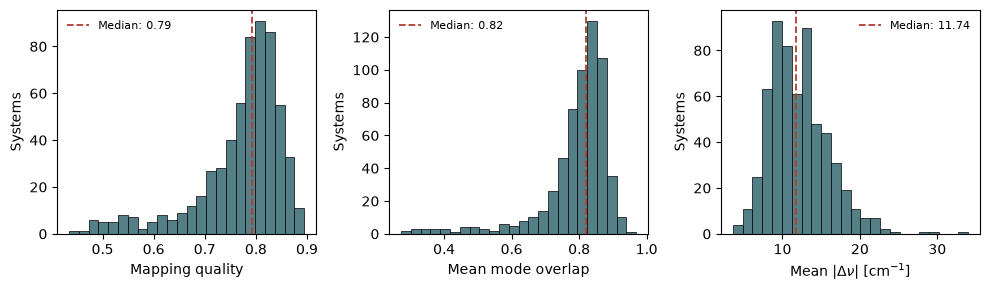

(<Figure size 1000x300 with 3 Axes>,
 array([<Axes: xlabel='Mapping quality', ylabel='Systems'>,
        <Axes: xlabel='Mean mode overlap', ylabel='Systems'>,
        <Axes: xlabel='Mean $|\\Delta\\nu|$ [cm$^{-1}$]', ylabel='Systems'>],
       dtype=object))

In [6]:
mapping_figure_path = figures_path + 'VNM_mapping_summary.png' if figures_path else None
plot_vnm_mapping_summary(valid_mapping_rows, output_path=mapping_figure_path)

## 3. Vibrational Thermodynamic Attribution

For every mapped mode pair, the harmonic entropy and enthalpy differences are partitioned into FCS, ligand, and metal contributions. Metal and ligand weights come from normalized atomic participation and therefore recover the complete molecular value exactly. The FCS contribution is a separate projection onto the 15-dimensional deformation space of the first coordination sphere. Individual ligands can receive different contributions even in homoleptic complexes because the optimized structures and normal modes need not preserve their equivalence; group comparisons therefore use the mean contribution per ligand.

### 3.1. System-resolved contributions

In [7]:
thermodynamic_path = outputs_path + 'unique_thermodynamic_data.csv'
thermodynamic_rows = read_csv(thermodynamic_path)
thermodynamic_by_refcode = {row['refcode']: row for row in thermodynamic_rows}

vnm_summary_path = outputs_path + 'vnm_thermodynamic_attribution_summary.csv'
vnm_bins_path = outputs_path + 'vnm_thermodynamic_attribution_bins.csv'

In [8]:
vnm_summary_rows = []
vnm_bin_rows = []
vnm_analysis_errors = []

for idx, system in enumerate(unique_systems):
    refcode = system.refcode_wo_digits

    try:
        thermodynamic_row = thermodynamic_by_refcode[refcode]
        vnm_mapping = vnm_mapping_by_refcode[refcode]
        hs_min = find_optimized_minimum(system.find_source('ref_hs_mol')[1])[1]

        molecule = hs_min.molecules[0]
        metal = molecule.metals[0]
        metal_index = metal.get_parent_index('molecule')
        fcs_indices = [metal_index] + metal.get_coord_sphere_idx()
        ligand_indices = [lig.get_parent_indices('molecule') for lig in molecule.ligands]

        grouped_indices = [metal_index]
        for indices in ligand_indices:
            grouped_indices.extend(indices)
        if sorted(grouped_indices) != list(range(len(molecule.atoms))):
            raise ValueError('Metal and ligand groups do not partition the molecule')

        hs_vnms = vnm_mapping['vnmsA_ordered']
        ls_vnms = vnm_mapping['vnmsB_ordered']
        alignment = vnm_mapping['alignment']
        pair_frequencies = 0.5 * np.asarray([
            hs_vnm.freq_cm + ls_vnm.freq_cm
            for hs_vnm, ls_vnm in zip(hs_vnms, ls_vnms)
        ])

        hs_mode_entropies = get_mode_entropies(hs_vnms, temperature)
        ls_mode_entropies = get_mode_entropies(ls_vnms, temperature)
        delta_mode_entropies = hs_mode_entropies - ls_mode_entropies
        hs_mode_enthalpies = get_mode_enthalpies(hs_vnms, temperature)
        ls_mode_enthalpies = get_mode_enthalpies(ls_vnms, temperature)
        delta_mode_enthalpies = hs_mode_enthalpies - ls_mode_enthalpies

        _, hs_fcs_weights, hs_fcs_basis = project_vnms_on_fcs(
            hs_vnms, alignment['coordsA'], fcs_indices
        )
        _, ls_fcs_weights, ls_fcs_basis = project_vnms_on_fcs(
            ls_vnms, alignment['coordsB'], fcs_indices
        )
        if hs_fcs_basis.shape[1] != 15 or ls_fcs_basis.shape[1] != 15:
            raise ValueError('The FeN6 internal basis does not contain 15 dimensions')
        delta_fcs_entropies = (
            hs_fcs_weights * hs_mode_entropies
            - ls_fcs_weights * ls_mode_entropies
        )
        delta_fcs_enthalpies = (
            hs_fcs_weights * hs_mode_enthalpies
            - ls_fcs_weights * ls_mode_enthalpies
        )

        hs_ligand_weights, hs_metal_weights = get_ligand_metal_weights(
            hs_vnms, ligand_indices, metal_index
        )
        ls_ligand_weights, ls_metal_weights = get_ligand_metal_weights(
            ls_vnms, ligand_indices, metal_index
        )
        hs_partition = np.sum(hs_ligand_weights, axis=1) + hs_metal_weights
        ls_partition = np.sum(ls_ligand_weights, axis=1) + ls_metal_weights
        if not np.allclose(hs_partition, 1.0) or not np.allclose(ls_partition, 1.0):
            raise ValueError('Ligand and metal participation does not sum to one')

        delta_ligand_entropies = (
            hs_ligand_weights * hs_mode_entropies[:, None]
            - ls_ligand_weights * ls_mode_entropies[:, None]
        )
        delta_all_ligand_entropies = np.sum(delta_ligand_entropies, axis=1)
        delta_mean_ligand_entropies = delta_all_ligand_entropies / len(ligand_indices)
        delta_metal_entropies = (
            hs_metal_weights * hs_mode_entropies
            - ls_metal_weights * ls_mode_entropies
        )
        if not np.allclose(delta_all_ligand_entropies + delta_metal_entropies, delta_mode_entropies):
            raise ValueError('Ligand and metal entropy does not recover the total entropy')

        delta_ligand_enthalpies = (
            hs_ligand_weights * hs_mode_enthalpies[:, None]
            - ls_ligand_weights * ls_mode_enthalpies[:, None]
        )
        delta_all_ligand_enthalpies = np.sum(delta_ligand_enthalpies, axis=1)
        delta_mean_ligand_enthalpies = delta_all_ligand_enthalpies / len(ligand_indices)
        delta_metal_enthalpies = (
            hs_metal_weights * hs_mode_enthalpies
            - ls_metal_weights * ls_mode_enthalpies
        )
        if not np.allclose(delta_all_ligand_enthalpies + delta_metal_enthalpies, delta_mode_enthalpies):
            raise ValueError('Ligand and metal enthalpy does not recover the total enthalpy')

        hs_all_ligand_weights = np.sum(hs_ligand_weights, axis=1)
        ls_all_ligand_weights = np.sum(ls_ligand_weights, axis=1)
        ligand_frequency_metrics = get_weighted_frequency_metrics(
            hs_vnms, ls_vnms, hs_all_ligand_weights, ls_all_ligand_weights
        )
        fcs_frequency_metrics = get_weighted_frequency_metrics(
            hs_vnms, ls_vnms, hs_fcs_weights, ls_fcs_weights
        )
        metal_frequency_metrics = get_weighted_frequency_metrics(
            hs_vnms, ls_vnms, hs_metal_weights, ls_metal_weights
        )

        homoleptic = thermodynamic_row['homoleptic'] == 'True'
        denticity = thermodynamic_row['denticity']
        analysis_group = f'd={denticity}' if homoleptic else 'heteroleptic'
        mapping_metrics = assess_vnm_mapping(vnm_mapping['mappings'])

        vnm_summary_rows.append({
            'refcode': refcode,
            'group': analysis_group,
            'homoleptic': homoleptic,
            'denticity': denticity,
            'num_ligands': len(ligand_indices),
            'temperature[K]': temperature,
            'dSvib_total[J·mol-1·K-1]': np.sum(delta_mode_entropies),
            'dSvib_FCS[J·mol-1·K-1]': np.sum(delta_fcs_entropies),
            'dSvib_all_ligands[J·mol-1·K-1]': np.sum(delta_all_ligand_entropies),
            'dSvib_mean_ligand[J·mol-1·K-1]': np.sum(delta_mean_ligand_entropies),
            'dSvib_metal[J·mol-1·K-1]': np.sum(delta_metal_entropies),
            'dHvib_total[kJ·mol-1]': np.sum(delta_mode_enthalpies),
            'dHvib_FCS[kJ·mol-1]': np.sum(delta_fcs_enthalpies),
            'dHvib_all_ligands[kJ·mol-1]': np.sum(delta_all_ligand_enthalpies),
            'dHvib_mean_ligand[kJ·mol-1]': np.sum(delta_mean_ligand_enthalpies),
            'dHvib_metal[kJ·mol-1]': np.sum(delta_metal_enthalpies),
            'HS_mean_nu_all_ligands[cm-1]': ligand_frequency_metrics['HS_mean_frequency'],
            'LS_mean_nu_all_ligands[cm-1]': ligand_frequency_metrics['LS_mean_frequency'],
            'dnu_all_ligands[cm-1]': ligand_frequency_metrics['dnu_mapped'],
            'HS_mean_nu_FCS[cm-1]': fcs_frequency_metrics['HS_mean_frequency'],
            'LS_mean_nu_FCS[cm-1]': fcs_frequency_metrics['LS_mean_frequency'],
            'dnu_FCS[cm-1]': fcs_frequency_metrics['dnu_mapped'],
            'HS_mean_nu_metal[cm-1]': metal_frequency_metrics['HS_mean_frequency'],
            'LS_mean_nu_metal[cm-1]': metal_frequency_metrics['LS_mean_frequency'],
            'dnu_metal[cm-1]': metal_frequency_metrics['dnu_mapped'],
            'num_positive_mode_pairs': fcs_frequency_metrics['num_mode_pairs'],
            'HS_FCS_projection_sum': np.sum(hs_fcs_weights),
            'LS_FCS_projection_sum': np.sum(ls_fcs_weights),
            'mapping_quality': mapping_metrics['mapping_quality'],
            'mean_overlap': mapping_metrics['mean_overlap'],
            'frequency_mae[cm-1]': mapping_metrics['frequency_mae'],
        })

        binned_values = {
            'dSvib_total[J·mol-1·K-1]': bin_mode_contributions(pair_frequencies, delta_mode_entropies, frequency_bins),
            'dSvib_FCS[J·mol-1·K-1]': bin_mode_contributions(pair_frequencies, delta_fcs_entropies, frequency_bins),
            'dSvib_all_ligands[J·mol-1·K-1]': bin_mode_contributions(pair_frequencies, delta_all_ligand_entropies, frequency_bins),
            'dSvib_mean_ligand[J·mol-1·K-1]': bin_mode_contributions(pair_frequencies, delta_mean_ligand_entropies, frequency_bins),
            'dSvib_metal[J·mol-1·K-1]': bin_mode_contributions(pair_frequencies, delta_metal_entropies, frequency_bins),
            'dHvib_total[kJ·mol-1]': bin_mode_contributions(pair_frequencies, delta_mode_enthalpies, frequency_bins),
            'dHvib_FCS[kJ·mol-1]': bin_mode_contributions(pair_frequencies, delta_fcs_enthalpies, frequency_bins),
            'dHvib_all_ligands[kJ·mol-1]': bin_mode_contributions(pair_frequencies, delta_all_ligand_enthalpies, frequency_bins),
            'dHvib_mean_ligand[kJ·mol-1]': bin_mode_contributions(pair_frequencies, delta_mean_ligand_enthalpies, frequency_bins),
            'dHvib_metal[kJ·mol-1]': bin_mode_contributions(pair_frequencies, delta_metal_enthalpies, frequency_bins),
        }
        for bin_index, (bin_low, bin_high) in enumerate(zip(frequency_bins[:-1], frequency_bins[1:])):
            bin_row = {
                'refcode': refcode,
                'group': analysis_group,
                'homoleptic': homoleptic,
                'denticity': denticity,
                'num_ligands': len(ligand_indices),
                'temperature[K]': temperature,
                'bin_low[cm-1]': bin_low,
                'bin_high[cm-1]': bin_high,
                'bin_label[cm-1]': f'{int(bin_low)}-{int(bin_high)}',
            }
            for column, values in binned_values.items():
                bin_row[column] = values[bin_index]
            vnm_bin_rows.append(bin_row)

        print(f'[{idx + 1}/{len(unique_systems)}] {refcode}: analysed')

    except Exception as exc:
        vnm_analysis_errors.append({'refcode': refcode, 'error': str(exc)})
        print(f'[{idx + 1}/{len(unique_systems)}] {refcode}: ERROR - {exc}')

[1/602] ABITEM: analysed
[2/602] ACAHUJ: analysed
[3/602] ADAQUU: analysed
[4/602] ADAREF: analysed
[5/602] ADEJOK: analysed
[6/602] ADEQIL: analysed
[7/602] ADEQOR: analysed
[8/602] AFANEB: analysed
[9/602] AFOYUS: analysed
[10/602] AGIZEX: analysed
[11/602] AHINUD: analysed
[12/602] AJAXEP: analysed
[13/602] AKEMUY: analysed
[14/602] AKENAF: analysed
[15/602] AKEQEM: analysed
[16/602] ALIKUC: analysed
[17/602] ALILEN: analysed
[18/602] ALUBOB: analysed
[19/602] AMIHUA: analysed
[20/602] APAFEH: analysed
[21/602] APINUJ: analysed
[22/602] ARADOO: analysed
[23/602] ARAGEH: analysed
[24/602] AROZIS: analysed
[25/602] ATASEU: analysed
[26/602] ATAVAU: analysed
[27/602] ATAVEY: analysed
[28/602] ATAXAW: analysed
[29/602] ATAXEB: analysed
[30/602] ATOZUG: analysed
[31/602] AWUKEK: analysed
[32/602] AXAKIT: analysed
[33/602] BADLIF: analysed
[34/602] BADWAG: analysed
[35/602] BAKGUR: analysed
[36/602] BALBIB: analysed
[37/602] BAXFIS: analysed
[38/602] BAXJUI: analysed
[39/602] BAXXAB: anal

In [9]:
summary_columns = [
    'refcode', 'group', 'homoleptic', 'denticity', 'num_ligands', 'temperature[K]',
    'dSvib_total[J·mol-1·K-1]', 'dSvib_FCS[J·mol-1·K-1]',
    'dSvib_all_ligands[J·mol-1·K-1]', 'dSvib_mean_ligand[J·mol-1·K-1]',
    'dSvib_metal[J·mol-1·K-1]',
    'dHvib_total[kJ·mol-1]', 'dHvib_FCS[kJ·mol-1]',
    'dHvib_all_ligands[kJ·mol-1]', 'dHvib_mean_ligand[kJ·mol-1]',
    'dHvib_metal[kJ·mol-1]',
    'HS_mean_nu_all_ligands[cm-1]', 'LS_mean_nu_all_ligands[cm-1]',
    'dnu_all_ligands[cm-1]',
    'HS_mean_nu_FCS[cm-1]', 'LS_mean_nu_FCS[cm-1]',
    'dnu_FCS[cm-1]', 'HS_mean_nu_metal[cm-1]',
    'LS_mean_nu_metal[cm-1]', 'dnu_metal[cm-1]', 'num_positive_mode_pairs',
    'HS_FCS_projection_sum', 'LS_FCS_projection_sum',
    'mapping_quality', 'mean_overlap', 'frequency_mae[cm-1]',
]
bin_columns = [
    'refcode', 'group', 'homoleptic', 'denticity', 'num_ligands', 'temperature[K]',
    'bin_low[cm-1]', 'bin_high[cm-1]', 'bin_label[cm-1]',
    'dSvib_total[J·mol-1·K-1]', 'dSvib_FCS[J·mol-1·K-1]',
    'dSvib_all_ligands[J·mol-1·K-1]', 'dSvib_mean_ligand[J·mol-1·K-1]',
    'dSvib_metal[J·mol-1·K-1]',
    'dHvib_total[kJ·mol-1]', 'dHvib_FCS[kJ·mol-1]',
    'dHvib_all_ligands[kJ·mol-1]', 'dHvib_mean_ligand[kJ·mol-1]',
    'dHvib_metal[kJ·mol-1]',
]
write_csv_rows(vnm_summary_path, vnm_summary_rows, summary_columns)
write_csv_rows(vnm_bins_path, vnm_bin_rows, bin_columns)

print(f'Analysed systems: {len(vnm_summary_rows)}')
print(f'Analysis errors:  {len(vnm_analysis_errors)}')
print(f'Summary output:   {vnm_summary_path}')
print(f'Binned output:    {vnm_bins_path}')

Analysed systems: 602
Analysis errors:  0
Summary output:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/vnm_thermodynamic_attribution_summary.csv
Binned output:    /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/vnm_thermodynamic_attribution_bins.csv


### 3.2. Entropy trends by denticity and composition

In [10]:
available_groups = [group for group in group_order if any(row['group'] == group for row in vnm_summary_rows)]
bin_labels = [f'{int(low)}-{int(high)}' for low, high in zip(frequency_bins[:-1], frequency_bins[1:])]

for group in available_groups:
    num_systems = sum(row['group'] == group for row in vnm_summary_rows)
    print(f'{group:<15} {num_systems:>4} systems')

entropy_metric_columns = {
    r'Total $\Delta S_{\mathrm{vib}}$': 'dSvib_total[J·mol-1·K-1]',
    'FCS attribution': 'dSvib_FCS[J·mol-1·K-1]',
    r'All-ligand attribution': 'dSvib_all_ligands[J·mol-1·K-1]',
    r'Metal attribution': 'dSvib_metal[J·mol-1·K-1]',
}
mean_entropy_by_metric = {}
for metric, column in entropy_metric_columns.items():
    mean_values = np.full((len(available_groups), len(bin_labels)), np.nan)
    for group_index, group in enumerate(available_groups):
        for bin_index, bin_label in enumerate(bin_labels):
            values = [
                float(row[column]) for row in vnm_bin_rows
                if row['group'] == group and row['bin_label[cm-1]'] == bin_label
            ]
            if values:
                mean_values[group_index, bin_index] = np.mean(values)
    mean_entropy_by_metric[metric] = mean_values

d=1               12 systems
d=2               50 systems
d=3              207 systems
d=6               30 systems
heteroleptic     303 systems


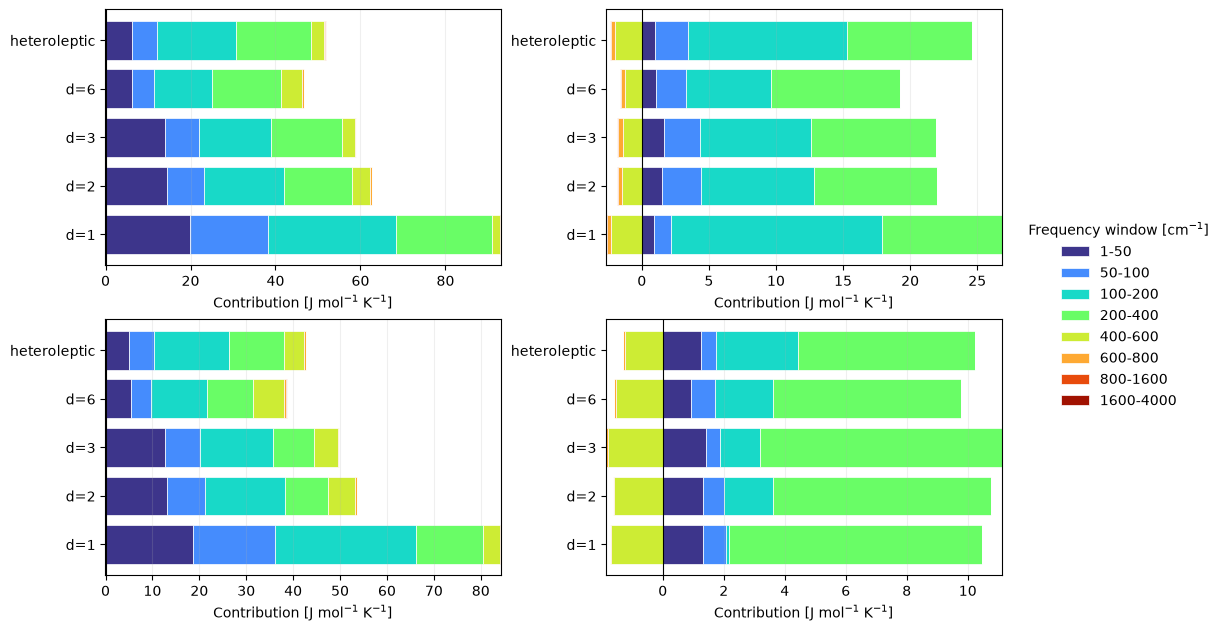

(<Figure size 1000x620 with 4 Axes>,
 array([<Axes: xlabel='Contribution [J mol$^{-1}$ K$^{-1}$]'>,
        <Axes: xlabel='Contribution [J mol$^{-1}$ K$^{-1}$]'>,
        <Axes: xlabel='Contribution [J mol$^{-1}$ K$^{-1}$]'>,
        <Axes: xlabel='Contribution [J mol$^{-1}$ K$^{-1}$]'>],
       dtype=object))

In [11]:
entropy_figure_path = figures_path + 'VNM_entropy_attribution_by_group.png' if figures_path else None
plot_binned_vnm_group_contributions(
    mean_entropy_by_metric,
    available_groups,
    bin_labels,
    r'Contribution [J mol$^{-1}$ K$^{-1}$]',
    output_path=entropy_figure_path,
    show_titles=False,
)

### 3.3. Enthalpy trends by denticity and composition

In [12]:
enthalpy_metric_columns = {
    r'Total $\Delta H_{\mathrm{vib}}$': 'dHvib_total[kJ·mol-1]',
    'FCS attribution': 'dHvib_FCS[kJ·mol-1]',
    r'All-ligand attribution': 'dHvib_all_ligands[kJ·mol-1]',
    r'Metal attribution': 'dHvib_metal[kJ·mol-1]',
}
mean_enthalpy_by_metric = {}
for metric, column in enthalpy_metric_columns.items():
    mean_values = np.full((len(available_groups), len(bin_labels)), np.nan)
    for group_index, group in enumerate(available_groups):
        for bin_index, bin_label in enumerate(bin_labels):
            values = [
                float(row[column]) for row in vnm_bin_rows
                if row['group'] == group and row['bin_label[cm-1]'] == bin_label
            ]
            if values:
                mean_values[group_index, bin_index] = np.mean(values)
    mean_enthalpy_by_metric[metric] = mean_values

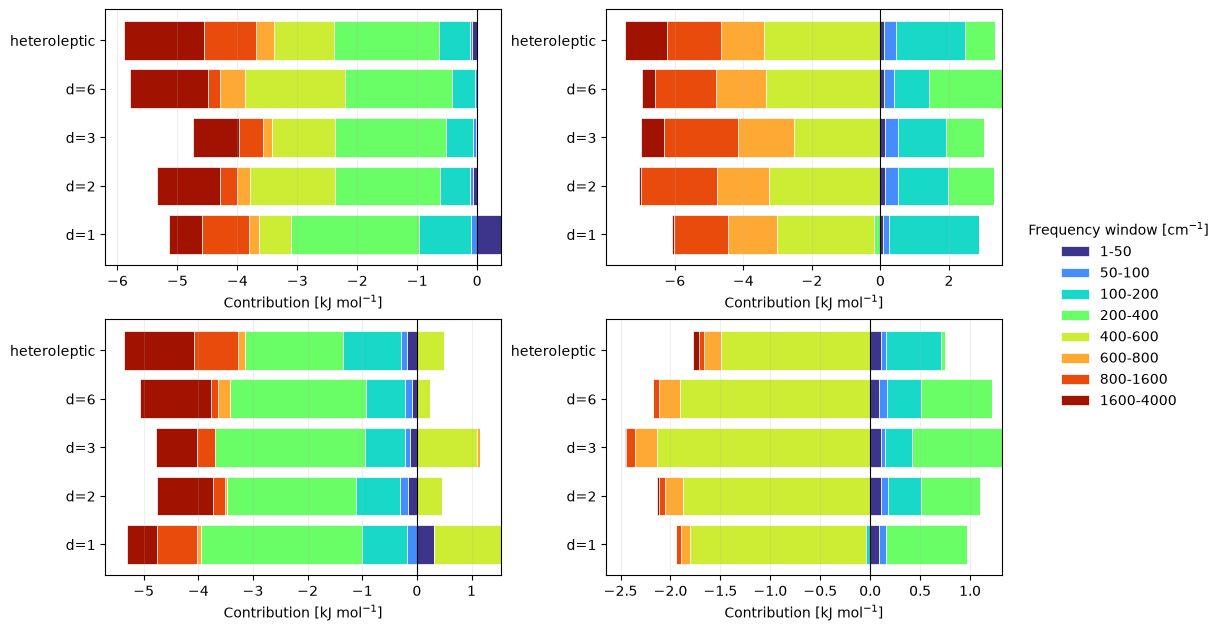

(<Figure size 1000x620 with 4 Axes>,
 array([<Axes: xlabel='Contribution [kJ mol$^{-1}$]'>,
        <Axes: xlabel='Contribution [kJ mol$^{-1}$]'>,
        <Axes: xlabel='Contribution [kJ mol$^{-1}$]'>,
        <Axes: xlabel='Contribution [kJ mol$^{-1}$]'>], dtype=object))

In [13]:
enthalpy_figure_path = figures_path + 'VNM_enthalpy_attribution_by_group.png' if figures_path else None
plot_binned_vnm_group_contributions(
    mean_enthalpy_by_metric,
    available_groups,
    bin_labels,
    r'Contribution [kJ mol$^{-1}$]',
    output_path=enthalpy_figure_path,
    show_titles=False,
)

### 3.4. Participation-weighted frequency shifts

For each mapped positive-frequency pair, $\Delta\nu_i=\nu_i^{\mathrm{HS}}-\nu_i^{\mathrm{LS}}$. The HS and LS mean frequencies use the same average HS/LS participation weights for all ligand atoms, the Fe atom, or the FCS, so $\Delta\bar{\nu}_G=\bar{\nu}_G^{\mathrm{HS}}-\bar{\nu}_G^{\mathrm{LS}}$ exactly. Negative shifts therefore indicate net softening upon LS-to-HS conversion.

In [14]:
frequency_metrics = [
    (
        'All ligands',
        'HS_mean_nu_all_ligands[cm-1]',
        'LS_mean_nu_all_ligands[cm-1]',
        'dnu_all_ligands[cm-1]',
    ),
    (
        'FCS',
        'HS_mean_nu_FCS[cm-1]',
        'LS_mean_nu_FCS[cm-1]',
        'dnu_FCS[cm-1]',
    ),
    (
        'Fe atom',
        'HS_mean_nu_metal[cm-1]',
        'LS_mean_nu_metal[cm-1]',
        'dnu_metal[cm-1]',
    ),
]

for label, hs_column, ls_column, shift_column in frequency_metrics:
    print(f'\n{label}')
    print(f"{'Group':<15} {'N':>4} {'HS mean':>12} {'LS mean':>12} {'Shift mean':>12}")
    for group in available_groups:
        group_rows = [row for row in vnm_summary_rows if row['group'] == group]
        hs_values = np.asarray([row[hs_column] for row in group_rows])
        ls_values = np.asarray([row[ls_column] for row in group_rows])
        shift_values = np.asarray([row[shift_column] for row in group_rows])
        print(
            f'{group:<15} {len(group_rows):>4} '
            f'{np.mean(hs_values):>12.2f} {np.mean(ls_values):>12.2f} '
            f'{np.mean(shift_values):>12.2f}'
        )


All ligands
Group              N      HS mean      LS mean   Shift mean
d=1               12      1158.95      1168.18        -9.23
d=2               50      1222.17      1229.66        -7.49
d=3              207      1183.13      1190.35        -7.22
d=6               30      1268.99      1278.06        -9.07
heteroleptic     303      1158.60      1167.30        -8.70

FCS
Group              N      HS mean      LS mean   Shift mean
d=1               12       721.80       749.78       -27.98
d=2               50       725.21       746.80       -21.60
d=3              207       739.21       760.72       -21.51
d=6               30       720.94       742.27       -21.33
heteroleptic     303       704.49       729.48       -25.00

Fe atom
Group              N      HS mean      LS mean   Shift mean
d=1               12       254.48       326.39       -71.91
d=2               50       262.32       317.47       -55.15
d=3              207       269.96       324.75       -54.80
d=6          

### 3.5. Representative monodentate and hexadentate systems

For each of the two limiting denticities, the representative is the real system closest to the class mean in the ligand-, FCS-, and Fe-weighted frequency shifts. Each metric is scaled by its within-class standard deviation before calculating the distance, so the selection is not dominated by the numerically largest shift.

d=1: YAGYUB
d=6: COTZUH


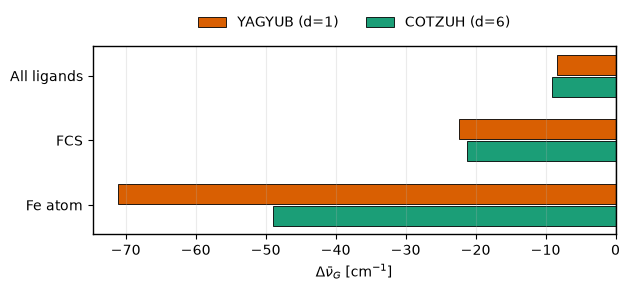

(<Figure size 640x300 with 1 Axes>,
 <Axes: xlabel='$\\Delta\\bar{\\nu}_G$ [cm$^{-1}$]'>)

In [15]:
representative_groups   = ['d=1', 'd=6']
selection_columns       = ['dnu_all_ligands[cm-1]', 'dnu_FCS[cm-1]', 'dnu_metal[cm-1]']
representative_rows     = []

for group in representative_groups:
    group_rows = [row for row in vnm_summary_rows if row['group'] == group]
    means = {column: np.mean([row[column] for row in group_rows]) for column in selection_columns}
    scales = {column: np.std([row[column] for row in group_rows]) for column in selection_columns}

    best_row = None
    best_distance = np.inf
    for row in group_rows:
        squared_differences = []
        for column in selection_columns:
            scale = scales[column] if scales[column] > 0.0 else 1.0
            squared_differences.append(((row[column] - means[column]) / scale) ** 2)
        distance = np.sqrt(np.mean(squared_differences))
        if distance < best_distance:
            best_row = row
            best_distance = distance

    representative_row = dict(best_row)
    representative_row['centroid_distance'] = best_distance
    representative_rows.append(representative_row)
    print(f"{group}: {representative_row['refcode']}")

representative_path = outputs_path + 'vnm_representative_frequency_shifts.csv'
representative_columns = [
    'refcode', 'group',
    'HS_mean_nu_all_ligands[cm-1]', 'LS_mean_nu_all_ligands[cm-1]', 'dnu_all_ligands[cm-1]',
    'HS_mean_nu_FCS[cm-1]', 'LS_mean_nu_FCS[cm-1]', 'dnu_FCS[cm-1]',
    'HS_mean_nu_metal[cm-1]', 'LS_mean_nu_metal[cm-1]', 'dnu_metal[cm-1]',
    'centroid_distance',
]
write_csv_rows(representative_path, representative_rows, representative_columns)

representative_figure_path = figures_path + 'VNM_representative_frequency_shifts.png' if figures_path else None
plot_representative_frequency_shifts(
    representative_rows,
    output_path=representative_figure_path,
)